In [1]:
import os
from pathlib import Path

import numpy as np
from PIL.ImageDraw2 import Draw
from matplotlib import pyplot as plt
from networkx.drawing import draw_networkx
from pydotthz import DotthzFile
from math_utils import get_fft, get_ifft
from scipy.signal import find_peaks
import scipy.constants
from tqdm.notebook import tqdm
import plotly.graph_objects as go
from plotly.subplots import make_subplots

import plotly.io as pio

pio.renderers.default = "notebook"
from scicolorscales import *
from scipy.optimize import curve_fit
import cmcrameri.cm as cmc

from thz_deconvolution import Deconvolution
from envelope import gaussian_kernel1d, convolve1d, envelope_hilbert
from estimate_noise import NoiseEstimator

from surface_extraction import detect_first_peak, get_thickness, get_thz_file_from_path
from pointcloud_helper import save_surface_as_point_cloud


In [2]:
#
path = Path("/Users/linus/Documents/COC_terrain/data_image_rfl")
# path = Path("/Users/linus/Documents/COC_SPHERES_fine_scan/data_image_rfl")
path = Path("/Users/linus/Documents/COC_SPHERES_fine_scan_3/data_image_rfl")
# path = Path("/Users/linus/Documents/COC_FULL_SPHERES_fine_scan/data_image_rfl")
# path = Path("/Users/linus/Documents/resolution_scan_A_high_res_6/data_image_rfl")
path = Path("/Users/linus/Documents/COC_SPHERES_ext_rng/data_image_rfl")
# path = Path("/Users/linus/Documents/COC_terrain_res_target_2/data_image_rfl")
# path = Path("/Users/linus/Documents/COC_terrain_res_target_5_c_coarse/data_image_rfl")
# path = Path("/Users/linus/Documents/COC_terrain_res_target_5_c_high_res/data_image_rfl")
# path = Path("/Users/linus/Documents/COC_terrain_res_target_4c/data_image_rfl")   # maybe focus issue?
# path = Path("/Users/linus/Documents/COC_terrain_res_target_4/data_image_rfl")  # maybe focus issue?
# path = Path("/Users/linus/Documents/COC_terrain_gaussian_1s/data_image_rfl") # maybe focus issue?
# path = Path("/Users/linus/Documents/COC_terrain_gaussian_1_high_res/data_image_rfl")
# path = Path("/Users/linus/Documents/COC_terrain_gaussian_2_high_res/data_image_rfl")
# path = Path("/Users/linus/Documents/COC_terrain_gaussian_3_high_res/data_image_rfl")
# path = Path("/Users/linus/Documents/COC_terrain_gaussian_4_high_res/data_image_rfl")
# path = Path("/Users/linus/Documents/COC_terrain_gaussian_5_high_res/data_image_rfl")
# path = Path("/Users/linus/Documents/DUST_surface_res_target_3d_3/data_image_rfl")
# ath = Path("/Users/linus/Documents/DUST_surface_res_target_3d_4/data_image_rfl")
#path = Path("/Users/linus/Documents/COC_PEBBLE_CoDA_T1a_2/data_image_rfl")
# path = Path("/Users/linus/Documents/Solid_ICE_PEBBLE_CoDA_T1a_2/data_image_rfl")
# path = Path("/Users/linus/Documents/SPIPA_ICE_PEBBLE_CoDA_T1a_2/data_image_rfl")
#path = Path("/Users/linus/Documents/COC_PEBBLE_CoDA_T3_dust_low_res_vac_4/data_image_rfl")
# path = Path("/Users/linus/Documents/COC_PEBBLE_CoDA_T3_dust_low_res_vac_5/data_image_rfl")

path = get_thz_file_from_path(path)

with DotthzFile(path) as psf_data:
    key = list(psf_data.keys())[0]
    dx = float(psf_data[key].metadata['dx [mm]'])
    dy = float(psf_data[key].metadata['dy [mm]'])
    x_min = float(psf_data[key].metadata['x_min [mm]'])
    x_max = float(psf_data[key].metadata['x_max [mm]'])
    y_min = float(psf_data[key].metadata['y_min [mm]'])
    y_max = float(psf_data[key].metadata['y_max [mm]'])
    width = int(float(psf_data[key].metadata['width']))
    height = int(float(psf_data[key].metadata['height']))
    datasets = psf_data[key].datasets

    # from the first dataset, extract the image:
    times = np.array(datasets["time"])
    traces = np.array(datasets["dataset"])

traces = traces[::, ::, :]

# Decon = Deconvolution(psf_path=Path("psf_data/psf.npz"), low_cut=0.1, high_cut=5.0)
Decon = Deconvolution(
    knife_edge_x_path=Path("psf_data/example_beam_width/measurement_x/data/1750085285.8557956_data.thz"),
    knife_edge_y_path=Path("psf_data/example_beam_width/measurement_y/data/1750163177.929295_data.thz"),
    low_cut=1.0, high_cut=4.0)

traces_old = traces
deconvolved_traces = Decon.apply_deconvolution(traces, x_min, x_max, width, y_min, y_max, height, max_iter=100)
traces = deconvolved_traces

p = traces[::, ::, times < 1912]
t = times[times < 1912]

p = traces[::, ::, :]
t = times[:]


Loading x raw measurements...
Loading y raw measurements...
Extracting the center of the PSF...
Center of the PSF: (-0.05000000000000071, -0.8499999999999996)
Creating 20 log-spaced filters...
Fitting beam widths...


100%|██████████| 20/20 [00:00<00:00, 74.09it/s]


Extracting the center of the PSF...
Center of the PSF: (-1.5500000000000003, -0.6500000000000004)
Creating 20 log-spaced filters...
Fitting beam widths...


100%|██████████| 20/20 [00:00<00:00, 54.74it/s]



Computing deconvolution (hash: 03f496db...)


100%|██████████| 20/20 [00:50<00:00,  2.50s/it]


In [ ]:
surface = np.zeros(p.shape[:2])

sigma = 10
kernel = gaussian_kernel1d(sigma=sigma, radius=sigma * 3)

n_components = 2
Gmm = NoiseEstimator(n_components=n_components)

stds = np.zeros((surface.shape[0], surface.shape[1], n_components))
mus = np.zeros((surface.shape[0], surface.shape[1], n_components))

for x in tqdm(range(p.shape[0])):
    for y in range(p.shape[1]):

        # f, a, arg = get_fft(t, p[x, y, :])
        #
        # a[f < 1.5] = 0
        # a[f > 5.0] = 0
        #
        # time, pulse = get_ifft(f, a, arg, t0=t[0])

        time, pulse = t, p[x, y, :]

        # convolved_data = convolve1d(np.abs(pulse), kernel)

        convolved_data = np.abs(scipy.signal.hilbert(np.abs(pulse)))

        threshold, components = Gmm.fit_lnmm_and_get_noise_threshold(convolved_data, std_multiplier=1, plot=False)
        mus[x][y] = components[0]
        stds[x][y] = components[1]
        # threshold = 0.7

        t1 = detect_first_peak(time, convolved_data, height=threshold)

        if t1 is None:
            t1 = t[-1]

        surface[x, y] = - get_thickness(t[0], t1) * 1000  # in mm

  0%|          | 0/120 [00:00<?, ?it/s]

  0%|          | 0/120 [00:00<?, ?it/s]

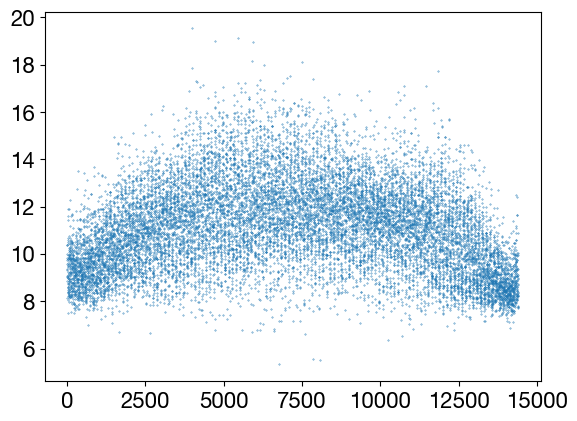

In [168]:
factors = []
factors2 = []
for x in tqdm(range(p.shape[0])):
    for y in range(p.shape[1]):
        time, pulse = t[t < 1912], p[x, y, t < 1912]
        time, pulse = t[:], p[x, y, :]
        convolved_data = convolve1d(np.abs(pulse), kernel)
        threshold = mus[x][y][0] + 5 * stds[x][y][0]
        # threshold = (threshold + mus[x][y][1] + 2 * stds[x][y][1]) / 2
        threshold = np.exp(mus[x][y][1] + 0.5 * stds[x][y][1] ** 2)
        # threshold = (mus[x][y][0]  + 5* stds[x][y][0]+  mus[x][y][1])/2.0
        dr = np.max(convolved_data) - np.min(convolved_data)
        factors.append((threshold - mus[x][y][0]) / stds[x][y][0])

        # threshold = threshold + 5*mus[x][y][0]

        t1 = detect_first_peak(time, convolved_data, height=threshold)

        factors2.append((threshold - mus[x][y][0]) / stds[x][y][0])

        if t1 is None:
            t1 = t[0]

        surface[x, y] = - get_thickness(t[0], t1) * 1000  # in mm

# plt.scatter(range(len(factors)), factors, s=0.1)
plt.scatter(range(len(factors)), factors2, s=0.1, marker="o")
plt.show()

nx, ny = surface.shape

# flip because of orientation
x_mm = np.linspace(0, y_max - y_min, ny)
y_mm = np.linspace(0, x_max - x_min, nx)
X, Y = np.meshgrid(x_mm, y_mm, indexing='xy')

# Create subplots
fig = make_subplots(
    rows=1, cols=1,
    subplot_titles=('Original Surface'),
    specs=[[{'type': 'surface'}]]
)

# Original surface
fig.add_trace(
    go.Surface(x=X, y=Y, z=surface, colorscale=vik, showscale=False),
    row=1, col=1
)

# Update layout
fig.update_layout(
    height=600,
    width=1400,
    scene=dict(
        xaxis_title='X [mm]',
        yaxis_title='Y [mm]',
        zaxis_title='Z [mm]',
        aspectmode='data'
    ),
)

fig.show()

In [162]:
x = 5
y = 5

time_trace, pulse_trace = t, p[x, y, :]
convolved_data = convolve1d(np.abs(pulse_trace), kernel)
threshold = mus[x][y][0] + 5 * stds[x][y][0]
threshold2 = mus[x][y][1] + stds[x][y][1]
t1 = detect_first_peak(time_trace, convolved_data, height=threshold)
fig = go.Figure()

# Original pulse trace
fig.add_trace(go.Scatter(x=time_trace, y=pulse_trace, mode='lines', name='Pulse'))

# Convolved data
fig.add_trace(go.Scatter(x=time_trace, y=convolved_data, mode='lines', name='Convolved'))

# Threshold line
fig.add_trace(go.Scatter(
    x=[time_trace[0], time_trace[-1]],
    y=[threshold, threshold],
    mode='lines',
    line=dict(dash='dash', color='red'),
    name='Threshold'
))

# Threshold line
fig.add_trace(go.Scatter(
    x=[time_trace[0], time_trace[-1]],
    y=[threshold2, threshold2],
    mode='lines',
    line=dict(dash='dash', color='yellow'),
    name='Threshold 2'
))

# Vertical line at detected peak
fig.add_trace(go.Scatter(
    x=[t1, t1],
    y=[min(pulse_trace), max(pulse_trace)],
    mode='lines',
    line=dict(dash='dot', color='orange'),
    name='Detected Peak'
))

fig.update_layout(
    xaxis_title='Time',
    yaxis_title='Signal',
    legend=dict(x=0.01, y=0.99)
)

fig.show()

x = 50
y = 50

time_trace, pulse_trace = t, p[x, y, :]
convolved_data = convolve1d(np.abs(pulse_trace), kernel)
threshold = mus[x][y][0] + 5 * stds[x][y][0]
threshold2 = mus[x][y][1] + stds[x][y][1]

t1 = detect_first_peak(time_trace, convolved_data, height=threshold)
fig = go.Figure()

# Original pulse trace
fig.add_trace(go.Scatter(x=time_trace, y=pulse_trace, mode='lines', name='Pulse'))

# Convolved data
fig.add_trace(go.Scatter(x=time_trace, y=convolved_data, mode='lines', name='Convolved'))

# Threshold line
fig.add_trace(go.Scatter(
    x=[time_trace[0], time_trace[-1]],
    y=[threshold, threshold],
    mode='lines',
    line=dict(dash='dash', color='red'),
    name='Threshold'
))

# Threshold line
fig.add_trace(go.Scatter(
    x=[time_trace[0], time_trace[-1]],
    y=[threshold2, threshold2],
    mode='lines',
    line=dict(dash='dash', color='yellow'),
    name='Threshold 2'
))

# Vertical line at detected peak
fig.add_trace(go.Scatter(
    x=[t1, t1],
    y=[min(pulse_trace), max(pulse_trace)],
    mode='lines',
    line=dict(dash='dot', color='orange'),
    name='Detected Peak'
))

fig.update_layout(
    xaxis_title='Time',
    yaxis_title='Signal',
    legend=dict(x=0.01, y=0.99)
)

fig.show()


In [163]:
save_surface_as_point_cloud(surface, x_max, x_min, y_max, y_min,
                            path.with_suffix(".ply"), format='ply')

Saving 14400 masked points to /Users/linus/Documents/COC_PEBBLE_CoDA_T3_dust_low_res_vac_4/data_image_rfl/1762940461.3184526_data.ply
Point cloud bounds: X[-32.00, 28.00], Y[-21.00, 39.00], Z[0.00, 15.89]
✅ Point cloud saved successfully!


(array([-32.        , -31.49579832, -30.99159664, ...,  26.99159664,
         27.49579832,  28.        ], shape=(14400,)),
 array([ 39.,  39.,  39., ..., -21., -21., -21.], shape=(14400,)),
 array([14.95761682, 14.98140072, 14.95761682, ..., 14.71981681,
        15.22711582, 15.2588341 ], shape=(14400,)))

In [164]:
def smoothen_surface_fft(surface, cutoff_fraction=0.1):
    """
    Smoothen surface using a Gaussian low-pass in the frequency domain.
    cutoff_fraction controls how much high-frequency content is preserved.
    """
    rows, cols = surface.shape
    fft_surface = np.fft.fftshift(np.fft.fft2(surface))

    y, x = np.ogrid[:rows, :cols]
    crow, ccol = rows // 2, cols // 2

    # Gaussian low-pass filter
    sigma = min(rows, cols) * cutoff_fraction / 2.0
    gaussian_mask = np.exp(-((x - ccol) ** 2 + (y - crow) ** 2) / (2 * sigma ** 2))

    fft_filtered = fft_surface * gaussian_mask
    surface_smoothed = np.fft.ifft2(np.fft.ifftshift(fft_filtered)).real

    return surface_smoothed


def smoothen_surface_gaussian(surface, sigma=3.0):
    """
    Smoothen a 2D surface using a Gaussian filter.
    sigma: standard deviation of the Gaussian kernel (higher = smoother)
    """
    return scipy.ndimage.gaussian_filter(surface, sigma=sigma)


# Apply smoothing
surface_smoothed = smoothen_surface_fft(surface, cutoff_fraction=0.6)
surface_smoothed = smoothen_surface_gaussian(surface, sigma=0.5)

# Save smoothed surface
export_path = Path("output_pointclouds")
os.makedirs(export_path, exist_ok=True)
save_surface_as_point_cloud(surface_smoothed, x_max, x_min, y_max, y_min,
                            export_path.joinpath(path.stem + "_smoothed.ply"), format='ply')


Saving 14400 masked points to output_pointclouds/1762940461.3184526_data_smoothed.ply
Point cloud bounds: X[-32.00, 28.00], Y[-21.00, 39.00], Z[0.00, 14.35]
✅ Point cloud saved successfully!


(array([-32.        , -31.49579832, -30.99159664, ...,  26.99159664,
         27.49579832,  28.        ], shape=(14400,)),
 array([ 39.,  39.,  39., ..., -21., -21., -21.], shape=(14400,)),
 array([13.4472496 , 13.45949336, 13.44266698, ..., 13.25219532,
        13.61691661, 13.73188902], shape=(14400,)))

In [165]:
# Create subplots
fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=('Original Surface', f'Smoothed (cutoff={0.3})'),
    specs=[[{'type': 'surface'}, {'type': 'surface'}]]
)

# Original surface
fig.add_trace(
    go.Surface(x=X, y=Y, z=surface, colorscale=berlin, showscale=False),
    row=1, col=1
)

# Smoothed surface
fig.add_trace(
    go.Surface(x=X, y=Y, z=surface_smoothed, colorscale=berlin),
    row=1, col=2
)

# Update layout
fig.update_layout(
    height=600,
    width=1400,
    scene=dict(
        xaxis_title='X [mm]',
        yaxis_title='Y [mm]',
        zaxis_title='Z [mm]',
        aspectmode='data'
    ),
    scene2=dict(
        xaxis_title='X [mm]',
        yaxis_title='Y [mm]',
        zaxis_title='Z [mm]',
        aspectmode='data'
    )
)

fig.show()


In [148]:
from typing import Optional
import os

import numpy as np
from typing import Optional
from pathlib import Path


def save_surface_as_point_cloud(
        surface,
        x_max,
        x_min,
        y_max,
        y_min,
        filename: Path,
        mask_radius: Optional[float] = None,
        format='txt',
        delete_quarter: bool = False,
        rotation_angles: Optional[np.ndarray] = None,  # [rx, ry, rz] in radians
        translation_vector: Optional[np.ndarray] = None
):
    """
    Save 2D surface data as a point cloud file, with optional rotation (angles) and translation.

    Args:
        surface: 2D numpy array with height values
        x_max, x_min, y_max, y_min: Physical dimensions in mm
        filename: Output filename
        format: 'txt', 'csv', 'xyz', or 'ply'
        rotation_angles: Optional 3-element array for rotation (radians) around X, Y, Z
        translation_vector: Optional 3-element numpy array for translation
    """
    nx, ny = surface.shape
    surface -= np.nanmin(surface)

    x_mm = np.linspace(y_min, y_max, ny)
    y_mm = np.linspace(-x_min, -x_max, nx)
    X, Y = np.meshgrid(x_mm, y_mm, indexing='xy')

    x_points = X.flatten()
    y_points = Y.flatten()
    z_points = surface.flatten()

    valid_mask = np.isfinite(z_points)
    x_points, y_points, z_points = x_points[valid_mask], y_points[valid_mask], z_points[valid_mask]

    if mask_radius is not None:
        width = x_max - x_min
        height = y_max - y_min
        radius = mask_radius * np.min([width, height]) / 2.0
        center_x = (y_max + y_min) / 2.0
        center_y = -(x_max + x_min) / 2.0
        mask = (x_points - center_x) ** 2 + (y_points - center_y) ** 2 <= radius ** 2
        x_points, y_points, z_points = x_points[mask], y_points[mask], z_points[mask]

    point_cloud = np.column_stack([x_points, y_points, z_points])

    # Apply rotation if provided
    if rotation_angles is not None:
        rx, ry, rz = rotation_angles
        # Rotation matrices
        Rx = np.array([
            [1, 0, 0],
            [0, np.cos(rx), -np.sin(rx)],
            [0, np.sin(rx), np.cos(rx)]
        ])
        Ry = np.array([
            [np.cos(ry), 0, np.sin(ry)],
            [0, 1, 0],
            [-np.sin(ry), 0, np.cos(ry)]
        ])
        Rz = np.array([
            [np.cos(rz), -np.sin(rz), 0],
            [np.sin(rz), np.cos(rz), 0],
            [0, 0, 1]
        ])
        R = Rz @ Ry @ Rx
        point_cloud = point_cloud @ R.T

    # Apply translation if provided
    if translation_vector is not None:
        point_cloud = point_cloud + translation_vector

    if delete_quarter:
        # Delete all points in the first quadrant (x > 0 and y > 0)
        mask = ~((point_cloud[:, 0] > 0) & (point_cloud[:, 1] > 0))
        point_cloud = point_cloud[mask]

    print(f"Saving {len(point_cloud)} masked points to {filename}")
    print(f"Point cloud bounds: X[{point_cloud[:, 0].min():.2f}, {point_cloud[:, 0].max():.2f}], "
          f"Y[{point_cloud[:, 1].min():.2f}, {point_cloud[:, 1].max():.2f}], "
          f"Z[{point_cloud[:, 2].min():.2f}, {point_cloud[:, 2].max():.2f}]")

    fmt = format.lower()
    if fmt in ('txt', 'csv', 'xyz'):
        delim = {'txt': ' ', 'csv': ',', 'xyz': ' '}[fmt]
        header = {'txt': 'X Y Z', 'csv': 'X,Y,Z', 'xyz': ''}[fmt]
        comments = {'txt': '# ', 'csv': '', 'xyz': ''}[fmt]
        np.savetxt(filename, point_cloud, fmt='%.6f', delimiter=delim, header=header, comments=comments)
    elif fmt == 'ply':
        with open(filename, 'w') as f:
            f.write("ply\nformat ascii 1.0\n")
            f.write(f"element vertex {len(point_cloud)}\n")
            f.write("property float x\nproperty float y\nproperty float z\nend_header\n")
            np.savetxt(f, point_cloud, fmt="%.6f")
    else:
        raise ValueError("Format must be 'txt', 'csv', 'xyz', or 'ply'")

    print("✅ Point cloud saved successfully!")
    return point_cloud[:, 0], point_cloud[:, 1], point_cloud[:, 2]


export_path = Path("output_pointclouds")
os.makedirs(export_path, exist_ok=True)

# terrain res target
# save_surface_as_point_cloud(surface_smoothed, x_max, x_min, y_max, y_min,
#                             export_path.joinpath(path.stem + "_smoothed.ply"),mask_radius=0.75, translation_vector=[2,-2.5,9], rotation_angles=[-np.radians(90),0,0], format='ply')

# save_surface_as_point_cloud(surface_smoothed, x_max, x_min, y_max, y_min,
#                              export_path.joinpath(path.stem + "_smoothed.ply"),mask_radius=0.75, translation_vector=[2,-3.2,9], rotation_angles=[-np.radians(90),-np.radians(3),0], format='ply')
#

# 10mm spheres
save_surface_as_point_cloud(surface_smoothed, x_max, x_min, y_max, y_min,
                           export_path.joinpath(path.stem + "_smoothed.ply"),mask_radius=0.75, translation_vector=[3,-1.0,8], rotation_angles=[-np.radians(90),0,0], format='ply')

# dust res target
# save_surface_as_point_cloud(surface_smoothed, x_max, x_min, y_max, y_min,
#                             export_path.joinpath(path.stem + "_smoothed.ply"),mask_radius=0.75, translation_vector=[-1,3.5,10], rotation_angles=[-np.radians(-90),np.radians(180),0], format='ply')

# full spheres target
# save_surface_as_point_cloud(surface_smoothed, x_max, x_min, y_max, y_min,
#                             export_path.joinpath(path.stem + "_smoothed.ply"),mask_radius=0.75, translation_vector=[5,-8,11], rotation_angles=[np.radians(-90),0,0], format='ply')



# gaussian 1 ( 5mm )
# translation = [2, -9, -3.2]
# rotation = [-np.radians(1), -np.radians(0.5), -np.radians(3)]

# # gaussian 2 ( 2.5mm )
# translation = [2, -9, -3.7]
# rotation = [-np.radians(0), np.radians(0.0), -np.radians(3)]
#
# # gaussian 3 ( 2mm )
# translation = [2, -9, -2.7]
# rotation = [-np.radians(0), np.radians(0.0), -np.radians(3)]
#
# # gaussian 4 ( 1.5mm )
# translation = [2, -9, -3.1]
# rotation = [-np.radians(0), np.radians(0), -np.radians(0)]
#
# # gaussian 5 ( 1.0mm )
# translation = [2, -9, -2.6]
# rotation = [-np.radians(0), np.radians(0.75), -np.radians(0)]

#
# save_surface_as_point_cloud(surface_smoothed, x_max, x_min, y_max, y_min,
#                             export_path.joinpath(path.stem + "_smoothed_2.ply"), mask_radius=0.75,
#                             translation_vector=translation,
#                             rotation_angles=rotation, format='ply')
#
# save_surface_as_point_cloud(surface_smoothed, x_max, x_min, y_max, y_min,
#                             export_path.joinpath(path.stem + "_smoothed_cropped_2.ply"), mask_radius=0.75,
#                             delete_quarter=True,
#                             translation_vector=translation,
#                             rotation_angles=rotation, format='ply')

Saving 25228 masked points to output_pointclouds/1761589074.661844_data_smoothed_2.ply
Point cloud bounds: X[-22.05, 22.94], Y[-22.32, 22.66], Z[-3.12, 2.16]
✅ Point cloud saved successfully!
Saving 18704 masked points to output_pointclouds/1761589074.661844_data_smoothed_cropped_2.ply
Point cloud bounds: X[-22.05, 22.93], Y[-22.32, 22.53], Z[-3.12, 2.16]
✅ Point cloud saved successfully!


(array([-1.77858756, -1.5287335 , -1.27815647, ..., -0.11131862,
         0.13937524,  0.39008987], shape=(18704,)),
 array([ 22.53290243,  22.52168658,  22.50881295, ..., -22.29814597,
        -22.31128749, -22.32447663], shape=(18704,)),
 array([0.74038172, 0.85003752, 0.86702009, ..., 1.38546507, 1.38747229,
        1.38681749], shape=(18704,)))